In [9]:
import sys
sys.path.append("..")

import pandas as pd
from src.common import load_train, RATING_COLS, RACINE


In [10]:
brut = pd.read_csv(RACINE / "data_raw" / "train.csv")
print(brut.shape)
print(brut.isna().sum().sum(), "valeurs manquantes")
print((brut[RATING_COLS] == 0).sum().sum(), "zéros dans les notes")


(103904, 25)
310 valeurs manquantes
15932 zéros dans les notes


In [11]:
df = load_train()
print(df.shape)
print("Taux d'insatisfaits :", df["insatisfait"].mean().round(4))
print("Retards à l'arrivée manquants :", df["Arrival Delay in Minutes"].isna().sum())
print("Notes sans réponse :", df[RATING_COLS].isna().sum().sum())

(103904, 23)
Taux d'insatisfaits : 0.5667
Retards à l'arrivée manquants : 0
Notes sans réponse : 15932


In [12]:
(RACINE / "data_clean").mkdir(exist_ok=True)
df.to_csv(RACINE / "data_clean" / "train_clean.csv", index=False)


In [13]:
import matplotlib.pyplot as plt

(RACINE / "figures").mkdir(exist_ok=True)


insatisfait
Neutre ou insatisfait    58879
Satisfait                45025
Name: count, dtype: int64


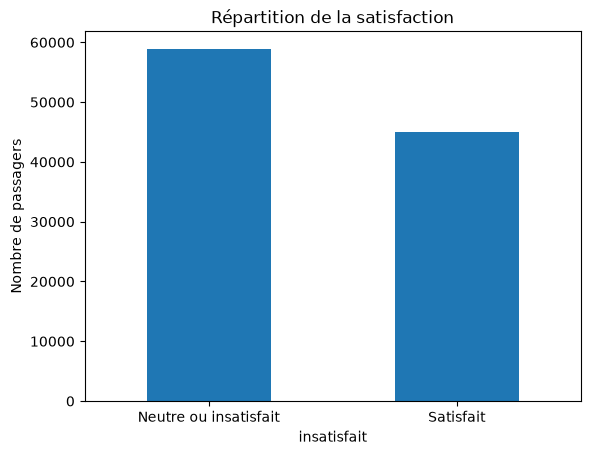

In [14]:
compte = df["insatisfait"].map({1: "Neutre ou insatisfait", 0: "Satisfait"}).value_counts()
print(compte)

compte.plot(kind="bar", rot=0)
plt.ylabel("Nombre de passagers")
plt.title("Répartition de la satisfaction")
plt.savefig(RACINE / "figures" / "01_cible.png", bbox_inches="tight")
plt.show()


In [15]:
for col in ["Type of Travel", "Class", "Customer Type"]:
    print((df.groupby(col)["insatisfait"].mean() * 100).round(1))
    print()


Type of Travel
Business travel    41.7
Personal Travel    89.8
Name: insatisfait, dtype: float64

Class
Business    30.6
Eco         81.4
Eco Plus    75.4
Name: insatisfait, dtype: float64

Customer Type
Loyal Customer       52.3
disloyal Customer    76.3
Name: insatisfait, dtype: float64



In [16]:
zeros = (brut[RATING_COLS] == 0).sum().sort_values(ascending=False)
print(zeros)


Departure/Arrival time convenient    5300
Ease of Online booking               4487
Inflight wifi service                3103
Online boarding                      2428
Leg room service                      472
Food and drink                        107
Inflight entertainment                 14
Cleanliness                            12
Inflight service                        3
On-board service                        3
Gate location                           1
Seat comfort                            1
Checkin service                         1
Baggage handling                        0
dtype: int64


In [17]:
sans_wifi = brut[brut["Inflight wifi service"] == 0]
print(len(sans_wifi), "passagers ont 0 au wifi")
print((sans_wifi["satisfaction"] == "satisfied").mean().round(3), "sont satisfaits")


3103 passagers ont 0 au wifi
0.997 sont satisfaits


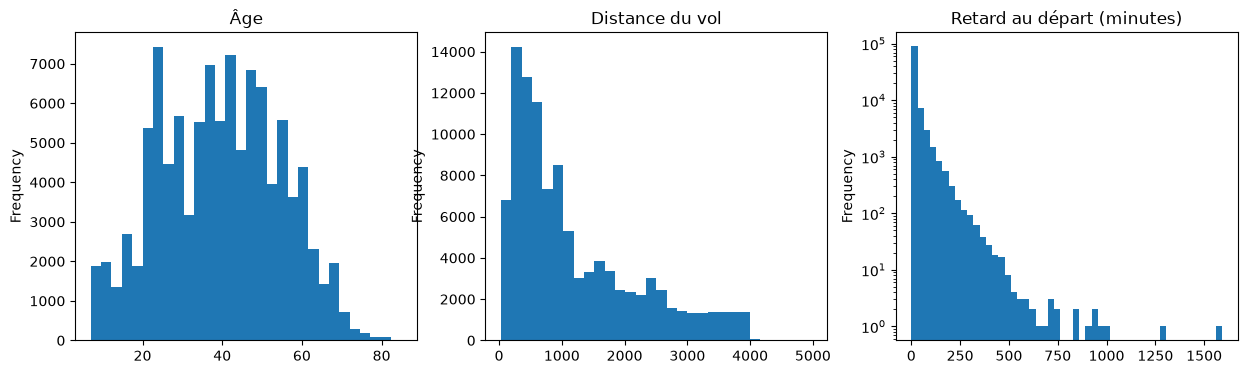

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.0,103904.0,103904.0,103904.0
mean,39.4,1189.4,14.8,15.2
std,15.1,997.1,38.2,38.8
min,7.0,31.0,0.0,0.0
25%,27.0,414.0,0.0,0.0
50%,40.0,843.0,0.0,0.0
75%,51.0,1743.0,12.0,13.0
max,85.0,4983.0,1592.0,1584.0


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["Age"].plot(kind="hist", bins=30, ax=axes[0], title="Âge")
df["Flight Distance"].plot(kind="hist", bins=30, ax=axes[1], title="Distance du vol")
df["Departure Delay in Minutes"].plot(kind="hist", bins=50, ax=axes[2], title="Retard au départ (minutes)", logy=True)
plt.savefig(RACINE / "figures" / "01_distributions.png", bbox_inches="tight")
plt.show()

df[["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]].describe().round(1)


In [19]:
tranches = pd.cut(df["Age"], bins=[0, 17, 25, 40, 60, 100],
                  labels=["moins de 18", "18-25", "26-40", "41-60", "plus de 60"])
print((df.groupby(tranches, observed=True)["insatisfait"].mean() * 100).round(1))
print((df["Age"] < 18).sum(), "mineurs")


Age
moins de 18    83.6
18-25          65.6
26-40          59.1
41-60          42.3
plus de 60     79.2
Name: insatisfait, dtype: float64
7931 mineurs


In [20]:
croise = df.pivot_table(index="Class", columns="Type of Travel", values="insatisfait", aggfunc="mean") * 100
croise.round(1)


Type of Travel,Business travel,Personal Travel
Class,,
Business,28.0,87.8
Eco,70.4,89.8
Eco Plus,60.7,91.3


In [21]:
print(df["Departure Delay in Minutes"].corr(df["Arrival Delay in Minutes"]).round(3))

retard = pd.cut(df["Arrival Delay in Minutes"], bins=[-1, 0, 15, 60, 2000],
                labels=["aucun", "1 à 15 min", "16 à 60 min", "plus d'1 h"])
print((df.groupby(retard, observed=True)["insatisfait"].mean() * 100).round(1))


0.966
Arrival Delay in Minutes
aucun          52.7
1 à 15 min     58.7
16 à 60 min    64.5
plus d'1 h     64.3
Name: insatisfait, dtype: float64
